# Khula! Maize Crop Health Classifier: Data Science Prototype

| | |
|---|---|
| **Name** | Gopolang Mmutlwane |
| **Module** | Data Science in Finance (DSF182) |
| **Assessment** | SS2, Part A |

This notebook builds a binary healthy/diseased classifier for maize leaf images, using a South African field-condition maize disease dataset. The prototype is proposed as a potential input to Khula!'s Funder Dashboard: a crop-health signal to complement the transaction-based risk data it currently relies on. Full justification, source links and an effectiveness assessment are in the accompanying report.

**Tutorial adapted:** PyTorch, *Transfer Learning for Computer Vision Tutorial* (https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html), "Finetuning the ConvNet" approach.

In [1]:
import os
import re
import sys
import time
import copy
import math
import hashlib
from collections import Counter
import pandas as pd
import numpy as np
from PIL import Image, UnidentifiedImageError
import PIL
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, confusion_matrix,
                             classification_report)
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [2]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"Random seed fixed at {SEED} for reproducibility.")

Random seed fixed at 42 for reproducibility.


In [3]:
# Versions used for this run; these must match requirements.txt
print("Python      ", sys.version.split()[0])
print("torch       ", torch.__version__)
print("torchvision ", torchvision.__version__)
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
print("Pillow      ", PIL.__version__)

Python       3.11.1
torch        2.14.0+cpu
torchvision  0.29.0+cpu
pandas       3.0.6
numpy        2.4.6
scikit-learn 1.9.1
matplotlib   3.11.2
Pillow       12.3.0


## Dataset Loading

**Source:** Maize_in_Field_Dataset, Kaggle (https://www.kaggle.com/datasets/hamishcrazeai/maize-in-field-dataset), licensed CC BY-NC-SA 4.0.

**Origin:** Craze, Pillay, Joubert & Berger (2022), *Plants*, 11(15), 1942 (https://doi.org/10.3390/plants11151942). The images are maize leaves photographed under real field conditions in Mpumalanga, KwaZulu-Natal and the Eastern Cape, South Africa.

**To run this notebook:** download the dataset from Kaggle and unzip it so that `data/Database.csv` and `data/leaf_images/` sit in the repository root (one level above this notebook). See `data/README.md`.

**Summary:** 2355 images, one CSV row per image. Each row has 8 label columns (GLS, NCLB, PLS, CR, SR, NoFoliarSymptoms, Other, UnidentifiedDisease), and an image can carry several labels at once. The binary healthy/diseased target is derived in Dataset Preprocessing. After derivation and duplicate removal, the dataset has 2102 diseased and 226 healthy images, an imbalance of about 9.3 : 1.

In [4]:
DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "Database.csv")
IMAGE_DIR = os.path.join(DATA_DIR, "leaf_images")

df = pd.read_csv(CSV_PATH)

print("Rows in CSV:", len(df))
print("Columns:", list(df.columns))
df.head()

Rows in CSV: 2355
Columns: ['imgID_id', 'filePath', 'GLS', 'NCLB', 'PLS', 'CR', 'SR', 'NoFoliarSymptoms', 'Other', 'UnidentifiedDisease']


,imgID_id,filePath,GLS,NCLB,PLS,CR,SR,NoFoliarSymptoms,Other,UnidentifiedDisease
0,1207,100_CIMG3835_1-135-2.JPG,1,0,0,0,0,0,0,0
1,1122,101_CIMG3836_1-49-1.JPG,1,0,0,0,0,0,0,0
2,1168,102_CIMG3837_1-49-2.JPG,1,0,0,0,0,0,0,0
3,1013,103_CIMG3838_1-43-1.JPG,1,0,0,0,0,0,0,0
4,1214,104_CIMG3839_1-43-2.JPG,1,0,0,0,0,0,0,0


In [5]:
df["file_exists"] = df["filePath"].apply(lambda f: os.path.exists(os.path.join(IMAGE_DIR, f)))
missing = df[~df["file_exists"]]

print(f"Rows with missing image files: {len(missing)}")
if len(missing) > 0:
    display(missing.head())

Rows with missing image files: 0


In [6]:
label_check_cols = ["GLS", "NCLB", "PLS", "CR", "SR", "NoFoliarSymptoms", "Other", "UnidentifiedDisease"]

unexpected_values = {}
for col in label_check_cols:
    bad = df[~df[col].isin([0, 1])]
    if len(bad) > 0:
        unexpected_values[col] = len(bad)

print("Columns with values outside {0, 1}:", unexpected_values if unexpected_values else "none")

duplicate_filepaths = df[df.duplicated("filePath", keep=False)]
print(f"Duplicate filePath entries in the CSV: {len(duplicate_filepaths)}")

Columns with values outside {0, 1}: none
Duplicate filePath entries in the CSV: 0


### Data-quality checks

The cell above confirms two things: every label column contains only 0/1 values (a missing or unexpected value would silently distort the label counts), and no filename appears twice in the CSV.

In [7]:
duplicate_ids = df[df.duplicated("imgID_id", keep=False)]
print(f"Duplicate imgID_id values: {len(duplicate_ids)}")

Duplicate imgID_id values: 0


The cell above confirms that `imgID_id` is unique, because it is used later to build group IDs for images with no extractable plot or date. A final check after the split confirms that every image lands in exactly one split.

### Raw label structure

This dataset is **multi-label**: a single image can carry more than one disease flag simultaneously (e.g. Gray Leaf Spot and Northern Corn Leaf Blight on the same leaf). The counts below report raw per-column totals across all 2355 images, before any derived target is constructed. The binary healthy/diseased target used for modelling will be derived in **Dataset Preprocessing**.

In [8]:
disease_cols = ["GLS", "NCLB", "PLS", "CR", "SR", "NoFoliarSymptoms", "Other", "UnidentifiedDisease"]

raw_counts = df[disease_cols].sum().sort_values(ascending=False)
print(f"Raw per-column positive counts (out of {len(df)} images):")
print(raw_counts)

label_cols_only = ["GLS", "NCLB", "PLS", "CR", "SR", "Other", "UnidentifiedDisease"]
multi_label_count = (df[label_cols_only].sum(axis=1) > 1).sum()
print(f"\nImages with more than one disease/other flag set: {multi_label_count}")

Raw per-column positive counts (out of 2355 images):
GLS                    1084
NCLB                    554
PLS                     493
UnidentifiedDisease     332
Other                   324
CR                      300
NoFoliarSymptoms        285
SR                       39
dtype: int64

Images with more than one disease/other flag set: 842


## Dataset Preprocessing

### Deriving the binary target

The raw CSV is multi-label. For this prototype we derive a single binary target, **healthy vs. diseased**, using the following explicit rule:

- `diseased = 1` if any of `[GLS, NCLB, PLS, CR, SR, Other, UnidentifiedDisease] == 1`
- `healthy = 1` if `NoFoliarSymptoms == 1` **and** all disease/other/unidentified columns are 0
- **Contradictions** (a row with `NoFoliarSymptoms == 1` *and* a disease flag also set) are resolved in favour of the disease flag, a false "healthy" label is the more consequential error for a funder-facing risk signal.
- **Fully unlabelled rows** (every column 0) carry no usable signal and are **dropped** before splitting. The exact count dropped is reported below.

In [9]:
label_cols = ["GLS", "NCLB", "PLS", "CR", "SR", "Other", "UnidentifiedDisease"]

df["any_disease"] = df[label_cols].any(axis=1)
df["healthy_flag"] = df["NoFoliarSymptoms"] == 1

n_contradictions = (df["any_disease"] & df["healthy_flag"]).sum()
n_unlabelled = (~df["any_disease"] & ~df["healthy_flag"]).sum()

print(f"Contradictory rows (disease flag + NoFoliarSymptoms both = 1): {n_contradictions}")
print(f"Fully unlabelled rows (to be dropped): {n_unlabelled}")

df["label"] = None
df.loc[df["any_disease"], "label"] = "diseased"
df.loc[df["healthy_flag"] & ~df["any_disease"], "label"] = "healthy"

n_before = len(df)
df = df.dropna(subset=["label"]).reset_index(drop=True)
n_after = len(df)
print(f"\nRows dropped as unlabelled: {n_before - n_after}")
print(f"Remaining labelled images: {n_after}")

Contradictory rows (disease flag + NoFoliarSymptoms both = 1): 53
Fully unlabelled rows (to be dropped): 0

Rows dropped as unlabelled: 0
Remaining labelled images: 2355


In [10]:
class_counts = df["label"].value_counts()
print("Derived class balance:")
print(class_counts)
print(f"\nImbalance ratio (majority:minority): {class_counts.max() / class_counts.min():.1f} : 1")

majority_class_accuracy = class_counts.max() / class_counts.sum()
print(f"\nMajority-class baseline accuracy: {majority_class_accuracy:.1%}")
print("(Accuracy at or below this does not, on its own, show the model has learned anything.)")

Derived class balance:
label
diseased    2123
healthy      232
Name: count, dtype: int64

Imbalance ratio (majority:minority): 9.2 : 1

Majority-class baseline accuracy: 90.1%
(Accuracy at or below this does not, on its own, show the model has learned anything.)


### Exploring filename conventions

Before attempting to extract a grouping key, a sample of raw filenames is inspected directly, to identify what structure, if any, they contain.

In [11]:
print("Random sample of raw filenames:")
print(df["filePath"].sample(20, random_state=1).to_string(index=False))

Random sample of raw filenames:
                      IMG_20190316_081710.jpg
                     159_CIMG3895_1-392-1.JPG
                      IMG_20190316_093028.jpg
   2012_03_IMG_6374_maize_diverse JM-C-Ac.JPG
   2012_03_IMG_6504_maize_diverse JM-R-Pn.JPG
                      IMG_20200302_111749.jpg
                          20200309_093538.jpg
                          20190313_111353.jpg
 2012_03_DSC1943_maize_diverse-R-Pn-DK-28.JPG
                     196_CIMG3932_1-124-2.JPG
        2019-03-13--Cedara-(DKB)-DSC_0247.JPG
2012_03_DSC1796_maize_diverse-C-AC-DK-273.JPG
   2012_03_IMG_6537_maize_diverse JM-R-Pn.JPG
                          20190313_141929.jpg
                     142_CIMG3878_1-125-1.JPG
                          20190313_141853.jpg
                          20200309_092553.jpg
                          20200309_101812.jpg
   2012_03_IMG_6453_maize_diverse JM-R-Pn.JPG
                      IMG_20200129_103646.jpg


### Extracting a plot/plant grouping key

To avoid near-duplicate leakage across train/validation/test splits, images need to be grouped by plant or plot rather than split individually at random. Two filename conventions are visible in an initial scan of the data: one embedding a plot number after a `1-` marker (e.g. `105_CIMG3840_1-140-1.JPG`), and one embedding a plot code before the file extension (e.g. `..._maize_diverse-C-AC-DK-273.JPG`). Both are extracted below, with the resulting match rate checked before relying on this as a complete grouping solution.

This first attempt is kept deliberately to show why a broader approach was needed. It is replaced by the three-tier version below.

In [12]:
def extract_group_id(filepath):
    # Naming convention 1: e.g. 105_CIMG3840_1-140-1.JPG to group "140"
    match_v1 = re.search(r'_1-(\d+)-\d+', filepath)
    if match_v1:
        return "v1_" + match_v1.group(1)
    
    # Naming convention 2: e.g. ..._maize_diverse-C-AC-DK-273.JPG to group "C-AC-DK-273"
    match_v2 = re.search(r'-([A-Za-z]+-[A-Za-z]+-[A-Za-z]+-\d+)\.JPG$', filepath)
    if match_v2:
        return "v2_" + match_v2.group(1)
    
    return None

df["group_id"] = df["filePath"].apply(extract_group_id)

matched = df["group_id"].notna().sum()
print(f"Filenames matching either group pattern: {matched} / {len(df)} ({matched/len(df):.1%})")
print(f"Filenames still unmatched (fallback to singleton): {len(df) - matched}")

# Give any remaining unmatched rows their own unique group (no leakage risk for these, since they don't share a confirmed identifier with anything else)
df.loc[df["group_id"].isna(), "group_id"] = "singleton_" + df.loc[df["group_id"].isna(), "imgID_id"].astype(str)

print(f"\nTotal unique groups: {df['group_id'].nunique()}")
print(f"Unique groups from pattern v1: {df['group_id'].str.startswith('v1_').sum()}")
print(f"Unique groups from pattern v2: {df['group_id'].str.startswith('v2_').sum()}")

Filenames matching either group pattern: 393 / 2355 (16.7%)
Filenames still unmatched (fallback to singleton): 1962

Total unique groups: 2064
Unique groups from pattern v1: 220
Unique groups from pattern v2: 173


In [13]:
unmatched = df[df["group_id"].str.startswith("singleton_")]

print(f"Total unmatched: {len(unmatched)}")
print("\nRandom sample of 40 unmatched filenames:")
print(unmatched["filePath"].sample(40, random_state=42).to_string(index=False))

Total unmatched: 1962

Random sample of 40 unmatched filenames:
                   IMG_20190316_081854.jpg
                              IMG_3634.JPG
     2019-03-13--Cedara-(DKB)-DSC_0205.JPG
     2019-03-13--Cedara-(DKB)-DSC_0138.JPG
                   IMG_20190227_112833.jpg
                   IMG_20190316_090331.jpg
2012_03_IMG_6424_maize_diverse JM-R-Pn.JPG
                   IMG_20190316_094010.jpg
                       20190313_113238.jpg
2012_03_IMG_6576_maize_diverse JM-R-Pn.JPG
                              IMG_3695.JPG
                   IMG_20190316_090350.jpg
                   IMG_20190316_082943.jpg
                   IMG_20190316_091951.jpg
                              IMG_3822.JPG
     2019-03-13--Cedara-(DKB)-DSC_0237.JPG
                       20190313_145907.jpg
                       20190313_111842.jpg
                   IMG_20190316_074305.jpg
     2019-03-13--Cedara-(DKB)-DSC_0071.JPG
                       20190313_145945.jpg
2012_03_IMG_6540_maize_diverse JM

### Refining the grouping key: three-tier extraction

The two-pattern approach above matched only 16.7% of filenames. A broader sample of the unmatched files revealed more naming conventions, reflecting different collection sessions and photographers. Each encodes grouping information differently, and some encode none at all:

- **Plot-level identifiers**, embedded in more than one format. These give the most precise grouping.
- **Session-level identifiers**, where there is no plot code but the filename contains a capture date. These group images by shoot day rather than by plant. Dates appear in two formats (`2019-03-13` and `20190313`), so both are normalised to `YYYYMMDD`. Otherwise photos taken on the same day with different cameras would be treated as separate groups and could land in different splits.
- **No extractable identifier**, for bare sequential filenames (e.g. `IMG_3634.JPG`). Each of these gets its own group, because there is no information to group them by.

The code below applies these tiers in order of precision and reports how many images fall into each.

In [14]:
def extract_group_id(filepath):
    # Tier 1a: e.g. 105_CIMG3840_1-140-1.JPG - plot "140"
    m = re.search(r'_1-(\d+)-\d+', filepath)
    if m:
        return "plot_" + m.group(1)

    # Tier 1b: e.g. ..._maize_diverse-C-AC-DK-273.JPG -> plot code
    m = re.search(r'-([A-Za-z]+-[A-Za-z]+-[A-Za-z]+-\d+)\.JPG$', filepath)
    if m:
        return "plot_" + m.group(1)

    # Tier 1c: e.g. ..._maize_diverse JM-R-Pn.JPG - plot code (space-separated variant)
    m = re.search(r'\s([A-Za-z]{1,3}-[A-Za-z]-[A-Za-z]{1,3})\.JPG$', filepath)
    if m:
        return "plot_" + m.group(1)

    # Tier 2: embedded capture date - session-level group.
    # Both date formats are normalised to YYYYMMDD so the same shoot day forms ONE group.
    m = re.search(r'(\d{4})-(\d{2})-(\d{2})', filepath)
    if m:
        return "session_" + "".join(m.groups())
    m = re.search(r'(\d{8})_\d+', filepath)
    if m:
        return "session_" + m.group(1)

    return None  # Tier 3: nothing extractable, handled below

df["group_id"] = df["filePath"].apply(extract_group_id)

n_plot = df["group_id"].str.startswith("plot_", na=False).sum()
n_session = df["group_id"].str.startswith("session_", na=False).sum()
n_singleton_needed = df["group_id"].isna().sum()

print(f"Tier 1 (plot-level): {n_plot} images ({n_plot/len(df):.1%})")
print(f"Tier 2 (session-level, by date): {n_session} images ({n_session/len(df):.1%})")
print(f"Tier 3 (no signal, singleton): {n_singleton_needed} images ({n_singleton_needed/len(df):.1%})")

df.loc[df["group_id"].isna(), "group_id"] = "singleton_" + df.loc[df["group_id"].isna(), "imgID_id"].astype(str)

print(f"\nTotal unique groups: {df['group_id'].nunique()}")

Tier 1 (plot-level): 619 images (26.3%)
Tier 2 (session-level, by date): 1475 images (62.6%)
Tier 3 (no signal, singleton): 261 images (11.1%)

Total unique groups: 375


### Image integrity check

File existence was already confirmed during Dataset Loading. This step goes further, opening every image to confirm it decodes correctly as a valid image file, catching any corrupted or truncated files before they can cause a failure during training.


In [15]:
def check_image_valid(filepath):
    try:
        with Image.open(os.path.join(IMAGE_DIR, filepath)) as img:
            img.verify()
        return True
    except (UnidentifiedImageError, OSError):
        return False

df["image_valid"] = df["filePath"].apply(check_image_valid)
invalid = df[~df["image_valid"]]

print(f"Images that failed to open/decode: {len(invalid)}")
if len(invalid) > 0:
    display(invalid[["filePath"]])

Images that failed to open/decode: 0


### Exact duplicate detection

Beyond grouping near-duplicate photos of the same plant, this step checks for exact, byte-for-byte duplicate image files saved under different filenames. An exact duplicate split across train and test would leak information more directly than the plot/session grouping alone protects against.

In [16]:
def file_hash(filepath):
    with open(os.path.join(IMAGE_DIR, filepath), "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["file_hash"] = df["filePath"].apply(file_hash)

duplicate_hashes = df[df.duplicated("file_hash", keep=False)]
n_duplicate_groups = duplicate_hashes["file_hash"].nunique()

print(f"Images involved in exact duplicates: {len(duplicate_hashes)}")
print(f"Number of distinct duplicate groups: {n_duplicate_groups}")

if len(duplicate_hashes) > 0:
    display(duplicate_hashes.sort_values("file_hash")[["filePath", "file_hash"]])

Images involved in exact duplicates: 54
Number of distinct duplicate groups: 27


,filePath,file_hash
606,2012_03_IMG_6543_maize_diverse JM (1)-R-Pn.JPG,01a44f961e3d468044a889edf4d4ea85
607,2012_03_IMG_6543_maize_diverse JM-R-Pn.JPG,01a44f961e3d468044a889edf4d4ea85
421,2012_03_IMG_6293_maize_diverse JM (1)-C-Ac.JPG,0b1e83e8da6a66a932f147421a3bc992
422,2012_03_IMG_6293_maize_diverse JM-C-Ac.JPG,0b1e83e8da6a66a932f147421a3bc992
373,2012_03_DSC1978_maize_diverse-R-Pn-DK-28.JPG,156e1cd63fffe15aaf1c0875573f9a07
372,2012_03_DSC1978_maize_diverse (1)-R-Pn-DK-28.JPG,156e1cd63fffe15aaf1c0875573f9a07
376,2012_03_DSC1981_maize_diverse-R-Pn-DK-28.JPG,18ca6df9e7e09b63267f52d86cbf7e87
375,2012_03_DSC1981_maize_diverse (1)-R-Pn-DK-28.JPG,18ca6df9e7e09b63267f52d86cbf7e87
337,2012_03_DSC1928_maize_diverse (1)-R-Pn-DK-28.JPG,198a5c75d551bd7cb7e9ec9569faf3b3
338,2012_03_DSC1928_maize_diverse-R-Pn-DK-28.JPG,198a5c75d551bd7cb7e9ec9569faf3b3


Exact duplicate detection surfaced 27 duplicate pairs (54 images), each following the same pattern: an otherwise identical filename with a "(1)" inserted, consistent with an accidental duplicate save or upload. After removing one image from each pair, 2,328 images remain. The original source paper (Craze, Pillay, Joubert & Berger, 2022, https://doi.org/10.3390/plants11151942) reports 2,332 images; the paper does not describe any deduplication step, so this discrepancy is noted but not explained by the published methodology.

One image from each duplicate pair is retained; the other is dropped before proceeding to the train/validation/test split.

In [17]:
# Prefer keeping the filename WITHOUT the "(1)" artifact where a duplicate pair exists
df["has_paren_marker"] = df["filePath"].str.contains(r"\(1\)", regex=True)
df_sorted = df.sort_values("has_paren_marker")  # clean filenames sort first

df = df_sorted.drop_duplicates(subset="file_hash", keep="first").sort_index().reset_index(drop=True)
df = df.drop(columns=["has_paren_marker"])

print(f"Images remaining after exact-duplicate removal: {len(df)}")

Images remaining after exact-duplicate removal: 2328


In [18]:
class_counts = df["label"].value_counts()
print("Class balance after deduplication:")
print(class_counts)
print(f"Imbalance ratio: {class_counts.max() / class_counts.min():.1f} : 1")

Class balance after deduplication:
label
diseased    2102
healthy      226
Name: count, dtype: int64
Imbalance ratio: 9.3 : 1


### Image size and format survey

A quick survey of image dimensions and file formats across the dataset, to confirm what the resize/normalization step in preprocessing needs to handle, rather than assuming uniformity.

In [19]:
sizes = []
formats = []

for fp in df["filePath"]:
    with Image.open(os.path.join(IMAGE_DIR, fp)) as img:
        sizes.append(img.size)
        formats.append(img.format)

size_counts = Counter(sizes)
format_counts = Counter(formats)

print("Distinct image dimensions found:", len(size_counts))
print("Most common dimensions (top 5):")
for size, count in size_counts.most_common(5):
    print(f"  {size}: {count} images")

print("\nFile formats found:")
print(format_counts)

Distinct image dimensions found: 14
Most common dimensions (top 5):
  (4032, 3024): 564 images
  (4288, 2848): 300 images
  (3840, 5120): 253 images
  (1920, 1280): 235 images
  (3648, 2736): 228 images

File formats found:
Counter({'JPEG': 2328})


In [20]:
orientations = ["portrait" if h > w else "landscape" if w > h else "square" for (w, h) in sizes]
orientation_counts = Counter(orientations)
print("Orientation breakdown:")
print(orientation_counts)

Orientation breakdown:
Counter({'landscape': 1889, 'portrait': 439})


Images are all JPEG but vary substantially in resolution (14 distinct dimensions, the five most common ranging from 1920×1280 to 3840×5120). This is consistent with the source paper's description of capture devices ranging from smartphones to a Nikon D90 SLR. Orientation is also mixed: 1,889 landscape images (81.1%) and 439 portrait (18.9%). That split is large enough to need deliberate handling in the transform step. A plain square resize would distort portrait and landscape images differently.

### Checking healthy-label distribution across groups

Before splitting by group, it is worth checking how the healthy images are spread across groups. If they sit in only a few groups, a plain group-based split could put most of them in one split by chance, leaving another split with too few, or zero, healthy examples to produce meaningful metrics.

In [21]:
n_healthy_total = (df["label"] == "healthy").sum()
healthy_by_group = df[df["label"] == "healthy"].groupby("group_id").size().sort_values(ascending=False)

print(f"Number of distinct groups containing at least one healthy image: {len(healthy_by_group)}")
print(f"Total groups overall: {df['group_id'].nunique()}")
print(f"\nTop 10 groups by healthy-image count:")
print(healthy_by_group.head(10))
print(f"\nHealthy images in the single largest group: {healthy_by_group.iloc[0]} "
      f"({healthy_by_group.iloc[0] / n_healthy_total:.1%} of all healthy images)")
print(f"Share of healthy images in the 4 largest healthy-containing groups: "
      f"{healthy_by_group.head(4).sum() / n_healthy_total:.1%}")

Number of distinct groups containing at least one healthy image: 19
Total groups overall: 361

Top 10 groups by healthy-image count:
group_id
session_20190313    96
session_20200309    68
session_20190316    16
plot_JM-R-Pn        10
plot_JM-C-Ac         9
plot_C-AC-DK-273     8
plot_R-Pn-DK-28      7
plot_387             1
session_20200129     1
singleton_1223       1
dtype: int64

Healthy images in the single largest group: 96 (42.5% of all healthy images)
Share of healthy images in the 4 largest healthy-containing groups: 84.1%


Healthy images are concentrated in very few groups: only 19 of the 361 groups contain any healthy image. The three largest of these are session-level (shoot-day) groups. The single largest, `session_20190313` (the two date formats merged), holds 96 healthy images, 42.5% of all healthy images, and the four largest healthy-containing groups together hold 84.1%. With this concentration, a plain group-based split could easily leave one split with a skewed or empty healthy class. `StratifiedGroupKFold`, which tries to balance classes while keeping groups intact, is therefore tested first below.

In [22]:

sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
_, demo_test_idx = next(sgkf_test.split(df.index.values, df["label"].values, df["group_id"].values))
demo_test_labels = df.iloc[demo_test_idx]["label"].value_counts()
print("StratifiedGroupKFold demo, resulting test-fold class balance:")
print(demo_test_labels)
print(f"Healthy images in this fold: {demo_test_labels.get('healthy', 0)}")

StratifiedGroupKFold demo, resulting test-fold class balance:
label
diseased    406
healthy      21
Name: count, dtype: int64
Healthy images in this fold: 21


### Train / validation / test split

`StratifiedGroupKFold` (demonstrated above) keeps groups intact, but on this dataset it did not give reliable class balance. The demo fold received 21 healthy images, under half its proportional share (about 45, one-fifth of 226). Informal tests of the full two-stage split (not reproduced here) left one split with no healthy images at all.

Groups are therefore assigned explicitly, in two stages:
1. Healthy-containing groups, largest first, each go to the split furthest below its healthy-image target (64% / 16% / 20%).
2. Diseased-only groups, largest first, each go to the split furthest below the total size implied by its healthy count.

The remaining imbalance is structural, not a coding problem. A few large session groups (575, 417 and 357 images) hold most of the healthy images and cannot be divided. Once they are placed, each split's size is largely fixed, and the diseased-only groups (the largest has only 39 images) cannot correct it. The result, printed below, is 64.7% / 9.1% / 26.2% instead of 64/16/20. The costs show up in the split check: the validation set is small (212 images, 26 healthy), and the test set's healthy share (5.9%) is about half the training set's (10.9%), which raises the test majority baseline to 94.1%. This trade-off is accepted because it keeps the two properties that matter most: every split has a non-zero healthy class, and no group appears in more than one split.

In [23]:
group_sizes = df.groupby("group_id").size()
group_healthy = df[df["label"] == "healthy"].groupby("group_id").size()

healthy_groups_sorted = group_healthy.sort_values(ascending=False).index.tolist()
diseased_only_groups_sorted = sorted(
    [g for g in group_sizes.index if g not in group_healthy.index],
    key=lambda g: group_sizes[g],
    reverse=True
)

target_frac = {"train": 0.64, "val": 0.16, "test": 0.20}
total_healthy = group_healthy.sum()
total_all = group_sizes.sum()
global_healthy_rate = total_healthy / total_all

split_healthy_count = {"train": 0, "val": 0, "test": 0}
split_total_count = {"train": 0, "val": 0, "test": 0}
split_groups = {"train": [], "val": [], "test": []}

# Stage 1: allocate healthy-containing groups, largest first
for g in healthy_groups_sorted:
    gaps = {s: target_frac[s] * total_healthy - split_healthy_count[s] for s in target_frac}
    chosen = max(gaps, key=gaps.get)
    split_groups[chosen].append(g)
    split_healthy_count[chosen] += group_healthy[g]
    split_total_count[chosen] += group_sizes[g]

# Stage 2: target total size derived from each split's OWN fixed healthy count
split_target_total = {s: split_healthy_count[s] / global_healthy_rate for s in target_frac}

for g in diseased_only_groups_sorted:
    gaps = {s: split_target_total[s] - split_total_count[s] for s in target_frac}
    chosen = max(gaps, key=gaps.get)
    split_groups[chosen].append(g)
    split_total_count[chosen] += group_sizes[g]

df_train = df[df["group_id"].isin(split_groups["train"])].reset_index(drop=True)
df_val = df[df["group_id"].isin(split_groups["val"])].reset_index(drop=True)
df_test = df[df["group_id"].isin(split_groups["test"])].reset_index(drop=True)

print(f"Train: {len(df_train)} ({len(df_train)/len(df):.1%})")
print(f"Val:   {len(df_val)} ({len(df_val)/len(df):.1%})")
print(f"Test:  {len(df_test)} ({len(df_test)/len(df):.1%})")

Train: 1507 (64.7%)
Val:   212 (9.1%)
Test:  609 (26.2%)


### Verifying the split

Two checks: that no group appears in more than one split (confirming the leakage protection worked), and the resulting class balance in each split.

In [24]:
train_groups = set(df_train["group_id"])
val_groups = set(df_val["group_id"])
test_groups = set(df_test["group_id"])

print(f"Group overlap train/val: {len(train_groups & val_groups)}")
print(f"Group overlap train/test: {len(train_groups & test_groups)}")
print(f"Group overlap val/test: {len(val_groups & test_groups)}")

print("\nClass balance per split:")
for name, split_df in [("Train", df_train), ("Val", df_val), ("Test", df_test)]:
    counts = split_df["label"].value_counts()
    total = counts.sum()
    print(f"\n{name} (n={total}):")
    print(counts)
    print(f"  healthy %: {counts.get('healthy', 0)/total:.1%}")

Group overlap train/val: 0
Group overlap train/test: 0
Group overlap val/test: 0

Class balance per split:

Train (n=1507):
label
diseased    1343
healthy      164
Name: count, dtype: int64
  healthy %: 10.9%

Val (n=212):
label
diseased    186
healthy      26
Name: count, dtype: int64
  healthy %: 12.3%

Test (n=609):
label
diseased    573
healthy      36
Name: count, dtype: int64
  healthy %: 5.9%


In [25]:
split_total = len(df_train) + len(df_val) + len(df_test)
print(f"Sum of split sizes: {split_total} | Original dataset size: {len(df)}")
print(f"Match: {split_total == len(df)}")

all_ids = set(df_train["imgID_id"]) | set(df_val["imgID_id"]) | set(df_test["imgID_id"])
no_duplicates = split_total == len(all_ids)
print(f"No image duplicated across splits (by imgID_id): {no_duplicates}")

Sum of split sizes: 2328 | Original dataset size: 2328
Match: True
No image duplicated across splits (by imgID_id): True


In [26]:
print("Sizes of all healthy-containing groups (largest first):")
print(group_sizes[group_healthy.index].sort_values(ascending=False))

print("\nSizes of the 15 largest diseased-only groups:")
print(group_sizes[diseased_only_groups_sorted[:15]])

Sizes of all healthy-containing groups (largest first):
group_id
session_20190313    575
session_20190316    417
session_20200309    357
plot_JM-R-Pn        120
plot_JM-C-Ac        106
plot_R-Pn-DK-28      82
plot_C-AC-DK-273     78
plot_387              5
session_20200129      3
singleton_1223        1
singleton_1225        1
singleton_1252        1
singleton_1294        1
singleton_1335        1
singleton_1342        1
singleton_1360        1
singleton_1413        1
singleton_1416        1
singleton_1445        1
dtype: int64

Sizes of the 15 largest diseased-only groups:
group_id
session_20190227    39
session_20200226    34
session_20200302    29
session_20200323    15
plot_153             4
plot_217             4
plot_7               4
plot_113             3
plot_121             3
plot_220             3
plot_238             3
plot_282             3
plot_298             3
plot_31              3
plot_314             3
dtype: int64


### Building a custom Dataset 

The tutorial loads images with `ImageFolder`, which needs them physically copied into `train/val/test` class folders. That was attempted first but failed with an out-of-disk-space error: these high-resolution images roughly double the disk space required when copied. The failing code is not included, because it would make this notebook fail on every run.

Instead, a custom `torch.utils.data.Dataset` reads images directly from the original `leaf_images` folder. It uses the `df_train` / `df_val` / `df_test` DataFrames from the grouped split to decide each image's split and label, so no files are duplicated. This is the one deliberate departure from the tutorial's data loading. The model architecture and optimiser settings are otherwise the tutorial's; the class-weighted loss and training-loop changes are explained in Model Training.

JPEGs are decoded at reduced scale (`Image.draft`) before resizing. The originals are up to 5120 px, and decoding them at full size every epoch made CPU training take over three hours. The final image is still resized to 224 px, so the model input is unchanged.

In [27]:
class MaizeLeafDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform
        self.class_to_idx = {"healthy": 0, "diseased": 1}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filePath"])
        image = Image.open(img_path)
        image.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))  # fast reduced-scale JPEG decode
        image = image.convert("RGB")
        label = self.class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

print("MaizeLeafDataset class defined.")
print("Class-to-index mapping:", {"healthy": 0, "diseased": 1})

MaizeLeafDataset class defined.
Class-to-index mapping: {'healthy': 0, 'diseased': 1}


### Transforms

The image size survey above showed images vary in both resolution (14 distinct dimensions) and orientation (about 81% landscape, 19% portrait). A plain resize to a fixed square would stretch the two orientations differently. Instead, each image's longer side is resized to 224 px (the input size ResNet18 was pretrained on) and the shorter side is padded, which preserves the aspect ratio.

Training images also get a random horizontal flip as basic augmentation, because the training set is small. Validation and test images get only resizing, padding and normalisation, with no augmentation, so evaluation reflects the model's real performance. Normalisation uses the ImageNet mean and standard deviation, as in the tutorial, because the pretrained weights expect inputs on that scale.

This replaces the tutorial's `RandomResizedCrop(224)` (training) and `Resize(256)` + `CenterCrop(224)` (validation). Those crop away part of the image, and on these leaf photos the cropped area can contain the very lesions the model needs to see.

In [28]:
IMG_SIZE = 224  # matches the pretrained ResNet18 input size

class ResizeWithPadding:
    """Resizes the longer side to `size` and pads the shorter side to
    make a square, preserving aspect ratio regardless of orientation."""
    def __init__(self, size=IMG_SIZE, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        w, h = img.size
        scale = self.size / max(w, h)
        new_w, new_h = int(round(w * scale)), int(round(h * scale))
        img = img.resize((new_w, new_h), Image.BILINEAR)

        pad_w = self.size - new_w
        pad_h = self.size - new_h
        padding = (pad_w // 2, pad_h // 2, pad_w - pad_w // 2, pad_h - pad_h // 2)
        return transforms.functional.pad(img, padding, fill=self.fill)

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

eval_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

print("Transforms defined.")

Transforms defined.


In [29]:
BATCH_SIZE = 32

train_dataset = MaizeLeafDataset(df_train, IMAGE_DIR, transform=train_transform)
val_dataset = MaizeLeafDataset(df_val, IMAGE_DIR, transform=eval_transform)
test_dataset = MaizeLeafDataset(df_test, IMAGE_DIR, transform=eval_transform)

# Seeded generator -> identical shuffle order on every Restart & Run All
train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)} ({len(train_dataset)} images)")
print(f"Val batches:   {len(val_loader)} ({len(val_dataset)} images)")
print(f"Test batches:  {len(test_loader)} ({len(test_dataset)} images)")

Train batches: 48 (1507 images)
Val batches:   7 (212 images)
Test batches:  20 (609 images)


## Model Training (**Tutorial-derived:** model architecture, loss/optimiser setup)

### Model, loss, optimiser and hyperparameters

The pretrained ResNet18 and its adaptation are taken directly from the PyTorch transfer-learning tutorial, using its first approach: fine-tuning all layers. This task has two classes (healthy vs. diseased), the same as the tutorial's ants vs. bees, so the final layer needs no structural change.

| Hyperparameter | Value | Tutorial | Reason |
|---|---|---|---|
| Optimiser | SGD, momentum 0.9 | same | A well-tested setting for fine-tuning a pretrained network; there was no evidence it needed changing. |
| Learning rate | 0.001 | same | Small enough not to destroy the pretrained features, since only the final layer starts from random weights. |
| LR schedule | StepLR, ×0.1 every 7 epochs | same | Lets the last few epochs settle at a lower rate. |
| Loss | CrossEntropyLoss, **class-weighted** | unweighted | With a ~9:1 imbalance, an unweighted loss can be minimised by mostly predicting "diseased". Weights inversely proportional to class frequency make each healthy error cost more. This does not guarantee the model beats the baseline; it only stops the loss from ignoring the minority class. |
| Batch size | **32** | 4 | The tutorial's 4 suits its ~240 training images. Here, with ~10% healthy, a batch of 4 usually contains no healthy image at all, while a batch of 32 typically contains about three, so most updates see both classes. It also trains much faster on CPU. |
| Epochs | **10** | 25 | An earlier 20-epoch run showed validation metrics plateaued by about epoch 6 while training accuracy reached ~99%, so further epochs only added overfitting. |
| Checkpoint selection | best **validation balanced accuracy** | best validation accuracy | Plain accuracy rewards always predicting "diseased" on a ~9:1 split; see the training loop below. |

In [30]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Re-seed right before model creation so the new final layer's starting weights are identical on every Restart & Run All
torch.manual_seed(SEED)

# Load pretrained ResNet18, adapt final layer for 2 classes (unchanged from the tutorial's own approach)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

# Class weights, computed from the actual training-set imbalance
train_label_counts = df_train["label"].value_counts()
weight_healthy = len(df_train) / (2 * train_label_counts["healthy"])
weight_diseased = len(df_train) / (2 * train_label_counts["diseased"])
class_weights = torch.tensor([weight_healthy, weight_diseased], dtype=torch.float32).to(device)

print(f"Class weights \n healthy: {weight_healthy:.3f}, diseased: {weight_diseased:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

print("Model, loss, and optimizer defined.")

Using device: cpu
Class weights 
 healthy: 4.595, diseased: 0.561
Model, loss, and optimizer defined.


### Training loop (**Adapted from tutorial:** extended to track history and select the best checkpoint by balanced accuracy)

The tutorial's `train_model()` only prints metrics and keeps the best checkpoint by plain validation accuracy. Two changes are made:

1. **History tracking.** Per-epoch train/validation loss, accuracy and validation balanced accuracy are stored for Results Visualisation.
2. **Checkpoint selection by validation balanced accuracy** (the average of healthy recall and diseased recall). On a ~9:1 split, plain accuracy rewards a model that always predicts "diseased", and in an earlier run validation loss turned out to be a poor selector too: it rose from epoch 1 onwards because the model became over-confident on a few mistakes, so loss-based selection kept an almost untrained epoch-1 model. Balanced accuracy weights both classes equally, which matches what the Funder Dashboard needs. The validation set contains few healthy images, so this choice is still somewhat noisy; the held-out test set is the real check.

In [31]:
def train_model(model, criterion, optimizer, scheduler, train_loader, val_loader, num_epochs=10, device=device):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_bal_acc = -1.0
    best_epoch = -1

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_bal_acc": []}
    dataloaders = {"train": train_loader, "val": val_loader}
    dataset_sizes = {"train": len(train_loader.dataset), "val": len(val_loader.dataset)}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")
        print("-" * 20)

        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()

            running_loss = 0.0
            running_corrects = 0
            phase_preds, phase_labels = [], []

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels).item()
                if phase == "val":
                    phase_preds.extend(preds.cpu().numpy())
                    phase_labels.extend(labels.cpu().numpy())

            if phase == "train":
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            if phase == "train":
                print(f"train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")
            else:
                epoch_bal_acc = balanced_accuracy_score(phase_labels, phase_preds)
                history["val_bal_acc"].append(epoch_bal_acc)
                print(f"val   Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} Balanced acc: {epoch_bal_acc:.4f}")

                if epoch_bal_acc > best_val_bal_acc:
                    best_val_bal_acc = epoch_bal_acc
                    best_epoch = epoch
                    best_model_wts = copy.deepcopy(model.state_dict())
        print()

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best validation balanced accuracy: {best_val_bal_acc:.4f} at epoch {best_epoch + 1}")

    model.load_state_dict(best_model_wts)
    return model, history, best_epoch

print("train_model defined: adds history tracking and balanced-accuracy checkpoint selection vs. the tutorial's original.")

train_model defined: adds history tracking and balanced-accuracy checkpoint selection vs. the tutorial's original.


In [32]:
model, history, best_epoch = train_model(
    model, criterion, optimizer, exp_lr_scheduler,
    train_loader, val_loader, num_epochs=10
)

Epoch 1/10
--------------------
train Loss: 0.5318 Acc: 0.7578
val   Loss: 0.6530 Acc: 0.8868 Balanced acc: 0.6543

Epoch 2/10
--------------------
train Loss: 0.4225 Acc: 0.8155
val   Loss: 1.2450 Acc: 0.8774 Balanced acc: 0.5662

Epoch 3/10
--------------------
train Loss: 0.2666 Acc: 0.8825
val   Loss: 1.1704 Acc: 0.8443 Balanced acc: 0.5639

Epoch 4/10
--------------------
train Loss: 0.2590 Acc: 0.8958
val   Loss: 1.1397 Acc: 0.8774 Balanced acc: 0.5993

Epoch 5/10
--------------------
train Loss: 0.1471 Acc: 0.9456
val   Loss: 0.8271 Acc: 0.8255 Balanced acc: 0.6689

Epoch 6/10
--------------------
train Loss: 0.0954 Acc: 0.9635
val   Loss: 1.2779 Acc: 0.8726 Balanced acc: 0.6462

Epoch 7/10
--------------------
train Loss: 0.0611 Acc: 0.9854
val   Loss: 1.5793 Acc: 0.8868 Balanced acc: 0.6212

Epoch 8/10
--------------------
train Loss: 0.0568 Acc: 0.9761
val   Loss: 1.5018 Acc: 0.8821 Balanced acc: 0.6185

Epoch 9/10
--------------------
train Loss: 0.0388 Acc: 0.9834
val   Los

### Reading the training run

- Training loss fell steadily from 0.53 to 0.04 and training accuracy rose to 98.7%, while validation loss rose from 0.65 to 1.86, reaching its lowest point after epoch 1 at epoch 5 (0.83). The model is memorising the training set rather than learning features that carry over to new images. This overfitting is expected with only 164 healthy training images.
- Validation accuracy stayed between 82.5% and 89.2% throughout, hovering around the validation set's own majority baseline (186 of 212 = 87.7%). Plain accuracy therefore says very little about whether the model is learning.
- Validation balanced accuracy peaked at 66.9% at epoch 5, so that checkpoint is kept. At epoch 5 validation accuracy was actually at its lowest (82.6%), because the model was predicting "healthy" more often: it caught more healthy leaves at the cost of a few more mistakes on diseased ones. After epoch 5, balanced accuracy drifted down to about 61% as overfitting continued.
- The validation set holds only 26 healthy images, so each one moves balanced accuracy by about 1.9 points. The choice of epoch 5 is therefore noisy, and the held-out test set below is the real check.
- Training took 54 minutes on CPU, down from over three hours before the reduced-scale JPEG decoding was added.

## Model Validation

The selected checkpoint is applied once to the held-out test set: images from groups never seen in training or validation. Metrics:

- **Accuracy vs. the majority-class baseline**, the score of always predicting "diseased", with a one-sided significance test.
- **Balanced accuracy**, where any trivial classifier scores 50%, with a bootstrap 95% confidence interval. On a ~9:1 test set this is the fairer measure of whether the model learned anything.
- **Per-class precision / recall / F1 and the confusion matrix**, to show *which* errors the model makes. For a funder-facing risk signal, the costly one is a diseased leaf predicted healthy.

In [33]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
test_bal_acc = balanced_accuracy_score(all_labels, all_preds)
test_counts = df_test["label"].value_counts()
majority_baseline = test_counts.max() / test_counts.sum()

print(f"Test accuracy:                {test_accuracy:.1%}")
print(f"Majority-class baseline:      {majority_baseline:.1%}")
print(f"Test balanced accuracy:       {test_bal_acc:.1%}  (trivial classifier = 50.0%)")

print("\nPer-class precision/recall/F1:")
print(classification_report(all_labels, all_preds, target_names=["healthy", "diseased"]))

cm = confusion_matrix(all_labels, all_preds)
print("Confusion matrix (rows=actual, cols=predicted, order=[healthy, diseased]):")
print(cm)

Test accuracy:                93.6%
Majority-class baseline:      94.1%
Test balanced accuracy:       58.8%  (trivial classifier = 50.0%)

Per-class precision/recall/F1:
              precision    recall  f1-score   support

     healthy       0.41      0.19      0.26        36
    diseased       0.95      0.98      0.97       573

    accuracy                           0.94       609
   macro avg       0.68      0.59      0.62       609
weighted avg       0.92      0.94      0.93       609

Confusion matrix (rows=actual, cols=predicted, order=[healthy, diseased]):
[[  7  29]
 [ 10 563]]


In [34]:
n = len(all_labels)
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# 1) Accuracy vs. majority baseline: one-sided z-test (SE under the null that model = baseline)
se_null = math.sqrt(majority_baseline * (1 - majority_baseline) / n)
z = (test_accuracy - majority_baseline) / se_null
p_value = 0.5 * math.erfc(z / math.sqrt(2))   # P(Z >= z)
print(f"Margin over baseline: {(test_accuracy - majority_baseline):+.1%}  "
      f"({z:+.2f} standard errors, one-sided p = {p_value:.3f})")

# 2) Balanced accuracy: bootstrap 95% confidence interval
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    if len(np.unique(y_true[idx])) == 2:
        boot.append(balanced_accuracy_score(y_true[idx], y_pred[idx]))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f"Balanced accuracy: {test_bal_acc:.1%}  (95% CI {ci_low:.1%} to {ci_high:.1%})")
print("-> CI is entirely above 50%: the model learned a real signal" if ci_low > 0.5
      else "-> CI includes 50%: no reliable signal beyond chance")

# 3) The funder-relevant error: diseased leaves predicted healthy (false 'all-clear')
false_all_clear = cm[1, 0]
n_diseased = cm[1].sum()
n_pred_healthy = cm[:, 0].sum()
print(f"\nDiseased leaves predicted healthy: {false_all_clear} of {n_diseased} ({false_all_clear / n_diseased:.1%})")
if n_pred_healthy > 0:
    print(f"'Healthy' predictions that were actually diseased: {false_all_clear} of {n_pred_healthy} "
          f"({false_all_clear / n_pred_healthy:.1%})")

Margin over baseline: -0.5%  (-0.52 standard errors, one-sided p = 0.697)
Balanced accuracy: 58.8%  (95% CI 52.7% to 65.6%)
-> CI is entirely above 50%: the model learned a real signal

Diseased leaves predicted healthy: 10 of 573 (1.7%)
'Healthy' predictions that were actually diseased: 10 of 17 (58.8%)


### Interpreting the test results

On a test set that is 94% diseased, plain accuracy is misleading: predicting "diseased" for every image already scores 94.1%. Balanced accuracy, where a trivial classifier scores 50%, shows whether the model has learned anything beyond the class distribution. For the Funder Dashboard, both error types carry a cost. A diseased leaf predicted healthy is a false "all-clear" that could make a risky loan look safe. A healthy leaf predicted diseased is a false alarm that could make a creditworthy farmer look risky, which works against Khula!'s aim of widening access to finance.

**Results:**
- **Accuracy:** 93.6% against a 94.1% majority baseline (−0.5 points, −0.52 standard errors, one-sided p = 0.697). The model does **not** beat always predicting "diseased".
- **Balanced accuracy:** 58.8% (95% CI 52.7%–65.6%). The interval sits just above 50%, so the model has learned a **real but weak** signal. 
- **What the model actually does:** it predicts "diseased" for 592 of 609 test images (97.2%). It recognises only 7 of 36 healthy leaves (healthy recall 19%) and flags the other 29 as diseased.
- **False all-clear:** only 10 of 573 diseased leaves (1.7%) were predicted healthy. This looks reassuring, but mainly because the model rarely says "healthy" at all. When it does, it is wrong 10 times out of 17 (58.8%; this matches the balanced-accuracy figure only by coincidence).

**Conclusion:** the model leans almost entirely on the majority class. Its main failure is flagging healthy crops as diseased, which would generate false risk flags for creditworthy farmers and quickly make the signal easy for funders to ignore. It is a workable proof of concept, but not reliable enough for production. Likely causes are the small number of healthy training images (164), the overfitting seen in the training curves, and, as the error breakdown in Results Visualisation shows, a failure to carry what it learned over to unseen shoot sessions and plots: every error comes from just three test groups, and two of them had none of their healthy leaves recognised.

## Results Visualisation

Four visuals, covering both training and unseen-data results:
1. **Training curves:** train vs. validation loss and accuracy per epoch, with validation balanced accuracy and the selected checkpoint marked. This shows the overfitting discussed in Model Training.
2. **Test confusion matrix:** where the unseen-data errors fall, especially diseased leaves predicted healthy.
3. **Sample test predictions:** adapted from the tutorial's `visualize_model()`.
4. **Examples of both error types:** healthy leaves predicted diseased (false alarms) and diseased leaves predicted healthy (false all-clear).

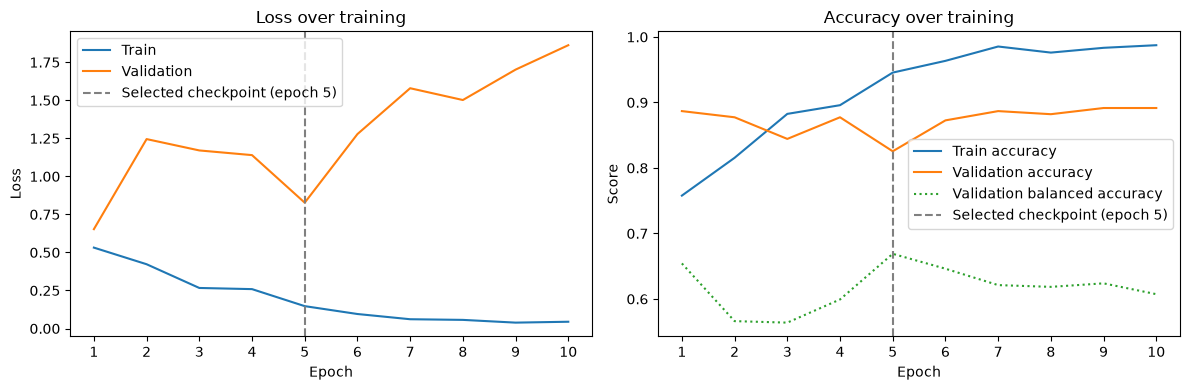

In [35]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].axvline(best_epoch + 1, color="gray", linestyle="--", label=f"Selected checkpoint (epoch {best_epoch+1})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss over training")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], label="Train accuracy")
axes[1].plot(epochs_range, history["val_acc"], label="Validation accuracy")
axes[1].plot(epochs_range, history["val_bal_acc"], label="Validation balanced accuracy", linestyle=":")
axes[1].axvline(best_epoch + 1, color="gray", linestyle="--", label=f"Selected checkpoint (epoch {best_epoch+1})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_title("Accuracy over training")
axes[1].legend()

for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

**Training curves.** In both panels, the gap between the training and validation lines is the overfitting described in Model Training: training loss keeps falling while validation loss climbs, and training accuracy approaches 99% while validation accuracy stays flat near its 87.7% baseline. The dotted line is validation balanced accuracy. It peaks at epoch 5 (dashed marker), the checkpoint used for testing, and declines after that.

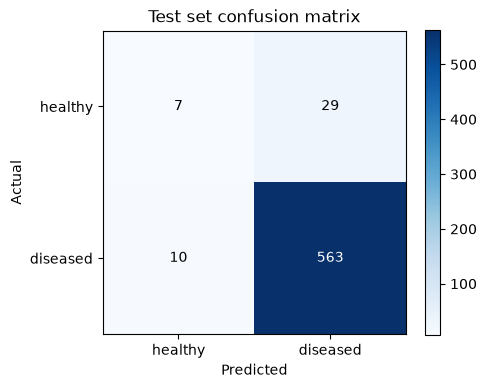

In [36]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

classes = ["healthy", "diseased"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Test set confusion matrix")

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")

plt.colorbar(im)
plt.tight_layout()
plt.show()

**Test confusion matrix.** Almost all predictions fall in the "diseased" column (592 of 609), and the bottom-right cell (563 diseased leaves correctly flagged) dominates, which is why overall accuracy looks high. The weakness is the top row: of 36 healthy test leaves, only 7 were recognised and 29 were flagged as diseased. The false all-clear cell (bottom left, 10) is small.

**Adapted from tutorial:** `imshow()` and `visualize_predictions()` (adapted from the tutorial's visualize_model())

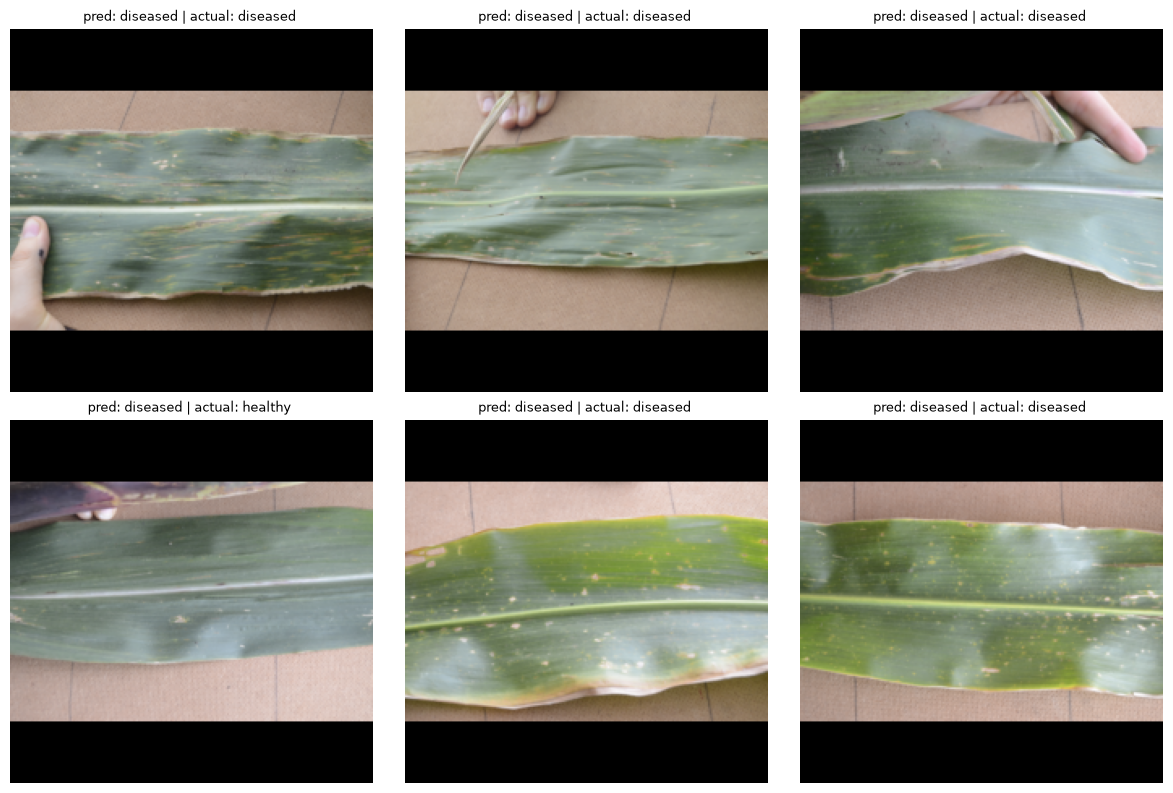

In [37]:
def imshow(inp, title=None):
    # Un-normalize and display a tensor image
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array(imagenet_mean)
    std = np.array(imagenet_std)
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title:
        plt.title(title, fontsize=9)
    plt.axis("off")

def visualize_predictions(model, dataloader, num_images=6, device=device):
    #Adapted from the tutorial's visualize_model().
    was_training = model.training
    model.eval()
    class_names = ["healthy", "diseased"]

    images_shown = 0
    fig = plt.figure(figsize=(12, 8))

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size(0)):
                images_shown += 1
                ax = plt.subplot(2, 3, images_shown)
                correct = preds[j] == labels[j]
                imshow(inputs.cpu().data[j], title=f"pred: {class_names[preds[j]]} | actual: {class_names[labels[j]]} ")
                if images_shown == num_images:
                    model.train(mode=was_training)
                    plt.tight_layout()
                    plt.show()
                    return
            if images_shown >= num_images:
                break

    model.train(mode=was_training)
    plt.tight_layout()
    plt.show()

visualize_predictions(model, test_loader, num_images=6)

**Sample predictions.** Five of the first six test images are diseased leaves correctly predicted as diseased. The other (bottom left) is a healthy leaf flagged as diseased, a small-scale version of the confusion matrix: the model says "diseased" almost every time. All six were photographed against the same cardboard background, because the test loader is not shuffled and each test group comes from a single plot or shoot session.

### Examining both error types

A sample of six images can look better or worse than the model really is, so the cell below deliberately shows both kinds of mistake from the test set, with filenames so each one can be checked against the source data:
- **Top row:** healthy leaves predicted diseased (false alarms), the model's most common error (29 cases).
- **Bottom row:** diseased leaves predicted healthy (false all-clear), 10 cases.

Healthy test leaves predicted diseased (false alarm):     29
Diseased test leaves predicted healthy (false all-clear): 10


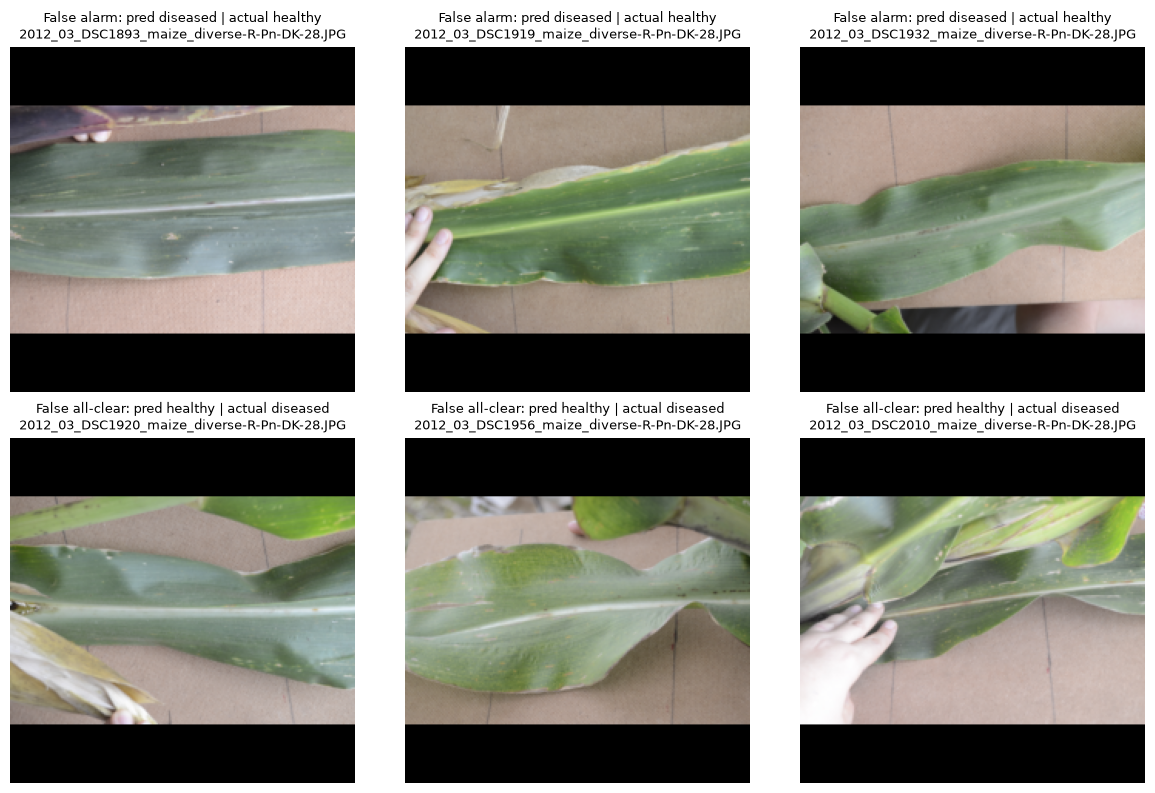

In [38]:
class_names = ["healthy", "diseased"]
fp_idx = [i for i, (y, p) in enumerate(zip(all_labels, all_preds)) if y == 0 and p == 1]  # healthy - diseased
fn_idx = [i for i, (y, p) in enumerate(zip(all_labels, all_preds)) if y == 1 and p == 0]  # diseased - healthy
print(f"Healthy test leaves predicted diseased (false alarm):     {len(fp_idx)}")
print(f"Diseased test leaves predicted healthy (false all-clear): {len(fn_idx)}")

n_show = 3
plt.figure(figsize=(4 * n_show, 8))
for r, (name, idx_list) in enumerate([("False alarm", fp_idx), ("False all-clear", fn_idx)]):
    for k, i in enumerate(idx_list[:n_show]):
        img, label = test_dataset[i]
        plt.subplot(2, n_show, r * n_show + k + 1)
        imshow(img, title=f"{name}: pred {class_names[all_preds[i]]} | actual {class_names[label]}\n"
                          f"{df_test.loc[i, 'filePath']}")
plt.tight_layout()
plt.show()

**Error examples.** All six examples come from the same 2012 plot (`R-Pn-DK-28`), photographed against cardboard. The false all-clear examples (bottom row) have lesions that are small and faint once the image is shrunk to 224 px, so they look like genuinely hard cases rather than obvious misses. The false alarms (top row) look healthy to the eye. What they do contain is shadow patches across the leaf surface, creases and folds, a frayed, discoloured edge (centre image), and stray hands, stems and neighbouring leaves in the frame, any of which could resemble disease at low resolution. Healthy and diseased leaves from this plot look almost identical at the model's input size, which suggests the model has not learned the fine lesion detail that separates them, and that higher-resolution inputs or tighter crops on the leaf would be worth testing.

In [39]:
errors = df_test.assign(pred=[class_names[p] for p in all_preds])
errors = errors[errors["label"] != errors["pred"]]
print(errors.groupby(["group_id", "label"]).size().rename("errors").sort_values(ascending=False))

group_id          label   
session_20190316  healthy     16
plot_R-Pn-DK-28   healthy      7
plot_JM-C-Ac      healthy      6
                  diseased     4
plot_R-Pn-DK-28   diseased     3
session_20190316  diseased     3
Name: errors, dtype: int64


**Where the errors fall.** All 39 test errors come from just three groups. In two of them, the model recognised none of the healthy leaves: all 16 healthy images from `session_20190316` and all 7 from `plot_R-Pn-DK-28` were flagged as diseased. In the third, `plot_JM-C-Ac`, 6 of 9 healthy images were flagged. The 10 false all-clears also fall in these three groups. The errors are therefore not random. The model appears to have learned what "healthy" looks like under the conditions of the training sessions (lighting, background, camera) rather than the leaf itself, and that does not carry over to a new shoot day or plot. A random image-level split would have hidden this, because photos from the same session would have appeared in both training and test. The group-based split is what exposes it. For Khula!, this is the most important limitation: farmers' photos would come from countless new "sessions", which is exactly the situation where this model fails.